# 07 — Robustness

**Workstream F.** Re-cuts the raw results frame from notebook 05 to test whether the conclusions of
notebook 06 hold up. The brief asks to *show whether conclusions depend on the sampled period or asset
subset*. Every comparison is **paired with EW in the same experiment**, as in Table 4.5.

| Task | Output | Status |
| --- | --- | --- |
| F1 | **Table 5.1 — Ranking under harsher costs** | Here |
| F2 | **Figure 5.1 — Paired Sharpe difference by evaluation year** | Here |
| F3 | **Table 5.2 — Sensitivity to period and subset**, period rows | Here |
| F4 | **Figure 5.2 — Paired results by asset held**; subset rows of Table 5.2 | Here |
| F5 | **Table 5.3 — Concentration** | Here |
| F6 | Limitations section, with **Table A5.2** as evidence for two of them | Here |

Appendix: **Table A5.1** gives Table 5.2's groups with the median Sharpe difference and the share with
lower volatility than EW. **Table A5.2** measures each strategy's exposure to the assets that went on to
beat the index, and its distribution yield (F6).

**These splits describe; they do not test.** The windows overlap in time and share assets, and each
period is paired with one subset, so the period and subset splits are not fully separable. Groups are
small (8 to 80 experiments), so a difference of 10–20 points between groups can be noise.

Helpers: `src/robustness.py`. Figures: `src/viz.py`.

## Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import backtest as bt
from src import config as cfg
from src import data, fmt, viz
from src import performance as pf
from src import robustness as rb
from src import strategies as st
from src.stylised import STRESS_LABEL, STRESS_WINDOW

viz.use_house_style()
np.random.seed(cfg.SEED)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 140)

#: As in notebook 06. The robustness checks ask whether *its* evidence holds.
RECOMMENDED = "ERC"
PCT = lambda dp: (lambda v: fmt.percent(v, dp))

---

## The grid

Rebuilt exactly as in notebook 05, which asserts that the rebuild is bit-identical.

In [2]:
close, volume, extraction_date = data.download_raw()
panel = data.build_panel(close, volume, extraction_date)
prices = panel.prices[cfg.ASSET_ORDER]
experiments = bt.sample_experiments(prices)

grid = pf.run_grid(prices, experiments, st.STRATEGIES, panel.risk_free)
results = pf.results_frame(grid, panel.risk_free)

d_sharpe = rb.paired_differences(results, "sharpe")   # experiments x 7 strategies, strategy minus EW
d_vol = rb.paired_differences(results, "ann_vol")

print(f"Extraction date : {panel.extraction_date.isoformat()}")
print(f"Seed            : {cfg.SEED}")
print(f"Runs            : {len(grid.runs):,}")
print(f"Evaluation years start {experiments['evaluation_start'].min().date()} to "
      f"{experiments['evaluation_start'].max().date()}")

Extraction date : 2026-10-19
Seed            : 20261001
Runs            : 800
Evaluation years start 2012-01-13 to 2025-09-15


---

## F1 — Table 5.1, ranking under harsher costs

Every run is repeated at twice the costs of definitions §6 (`cfg.COST_STRESS_MULTIPLIER`). The 2× runs
trade exactly as the 1× runs, because costs never change a weight decision (notebook 05), so any change
comes from the cost deducted alone. Rank 1 is the highest median net Sharpe, the ordering of Table 4.2.
The paired win rate against EW is shown at both cost levels, because the recommendation rests on it.

In [3]:
table_5_1 = rb.cost_ranking(results)
print("Table 5.1 - Ranking under harsher costs. Rank by median net Sharpe across the 100 experiments (1 = highest), "
      f"at the costs of definitions §6 (1x) and at {cfg.COST_STRESS_MULTIPLIER:g}x those costs. Beats EW: share of "
      "experiments in which the strategy's net Sharpe exceeds EW's in the same experiment.")
display(fmt.style(table_5_1, {"Rank 1x": fmt.count, "Rank 2x": fmt.count,
                              "Net Sharpe 1x": lambda v: fmt.number(v, 2), "Net Sharpe 2x": lambda v: fmt.number(v, 2),
                              "Beats EW (Sharpe) % 1x": PCT(0), "Beats EW (Sharpe) % 2x": PCT(0)}))

rank_moves = int((table_5_1["Rank 1x"] != table_5_1["Rank 2x"]).sum())
win_moves = (table_5_1["Beats EW (Sharpe) % 2x"] - table_5_1["Beats EW (Sharpe) % 1x"]).abs().max()
extra = pd.DataFrame({
    "Sharpe lost to the extra cost": (results[("net_2x", "sharpe")] - results[("net", "sharpe")]).groupby("strategy").median(),
    "Extra cost bp/yr": ((results[("net", "ann_return")] - results[("net_2x", "ann_return")]) * 1e4).groupby("strategy").median(),
}).reindex(cfg.STRATEGY_ORDER)
gaps = table_5_1["Net Sharpe 1x"].sort_values(ascending=False).diff().abs().dropna()
print(f"Strategies whose rank changes: {rank_moves}. Largest change in win rate: {win_moves:.0f} pp.")
print("Medians of the per-experiment change from 1x to 2x costs:")
display(fmt.style(extra, {"Sharpe lost to the extra cost": lambda v: fmt.number(v, 3),
                          "Extra cost bp/yr": lambda v: fmt.number(v, 1)}))
print(f"Gaps in median Sharpe between neighbours in the ranking: {gaps.min():.3f} to {gaps.max():.3f}.")

Table 5.1 - Ranking under harsher costs. Rank by median net Sharpe across the 100 experiments (1 = highest), at the costs of definitions §6 (1x) and at 2x those costs. Beats EW: share of experiments in which the strategy's net Sharpe exceeds EW's in the same experiment.


,Rank 1x,Rank 2x,Net Sharpe 1x,Net Sharpe 2x,Beats EW (Sharpe) % 1x,Beats EW (Sharpe) % 2x
strategy,,,,,,
EW,3,3,1.00,1.00,—,—
GMV,6,6,0.93,0.92,42,41
MV,8,8,0.57,0.56,30,30
MSR,7,7,0.69,0.69,30,30
IV,5,5,0.99,0.98,39,39
ERC,4,4,0.99,0.99,46,46
MDP,2,2,1.01,1.00,45,45
MDC,1,1,1.02,1.02,44,44


Strategies whose rank changes: 0. Largest change in win rate: 1 pp.
Medians of the per-experiment change from 1x to 2x costs:


,Sharpe lost to the extra cost,Extra cost bp/yr
strategy,,
EW,-0.003,4.0
GMV,-0.005,5.6
MV,-0.006,14.3
MSR,-0.007,11.9
IV,-0.003,4.1
ERC,-0.003,4.1
MDP,-0.005,5.4
MDC,-0.004,5.7


Gaps in median Sharpe between neighbours in the ranking: 0.005 to 0.236.


**Doubling costs changes nothing that matters.** No strategy changes rank, and no win rate against EW
moves by more than one point (printed above). The extra cost takes under 0.01 of median Sharpe from
any strategy. Costs are 2–3 bp one-way on liquid large caps and ETFs (definitions §6), so even MV, at
349% turnover a year, pays only about 14 bp a year more at 2×. Costs separate the strategies by
turnover, and the high-turnover strategies already trail.

**Two caveats on reading the ranks.** MDC, MDP, EW, ERC and IV sit within 0.03 of one another in median Sharpe,
so their order is a near tie at either cost level, not a ranking. And Table 4.2's median is taken
column by column: the paired win rate is the head-to-head measure, and it is just as stable.
**The recommendation does not depend on the cost assumption:** ERC turns over 31% a year, close to
EW's 20%.

---

## F2 — Figure 5.1, paired Sharpe difference by evaluation year

Each dot is one experiment: the strategy's net Sharpe minus EW's in the same experiment, placed at the
start of its evaluation year (the year the metrics measure). Above the dashed line the strategy beat
EW. The dark line is the median by calendar year of the evaluation start. The grey band marks the
evaluation starts whose year contains the March 2020 crash (F3).

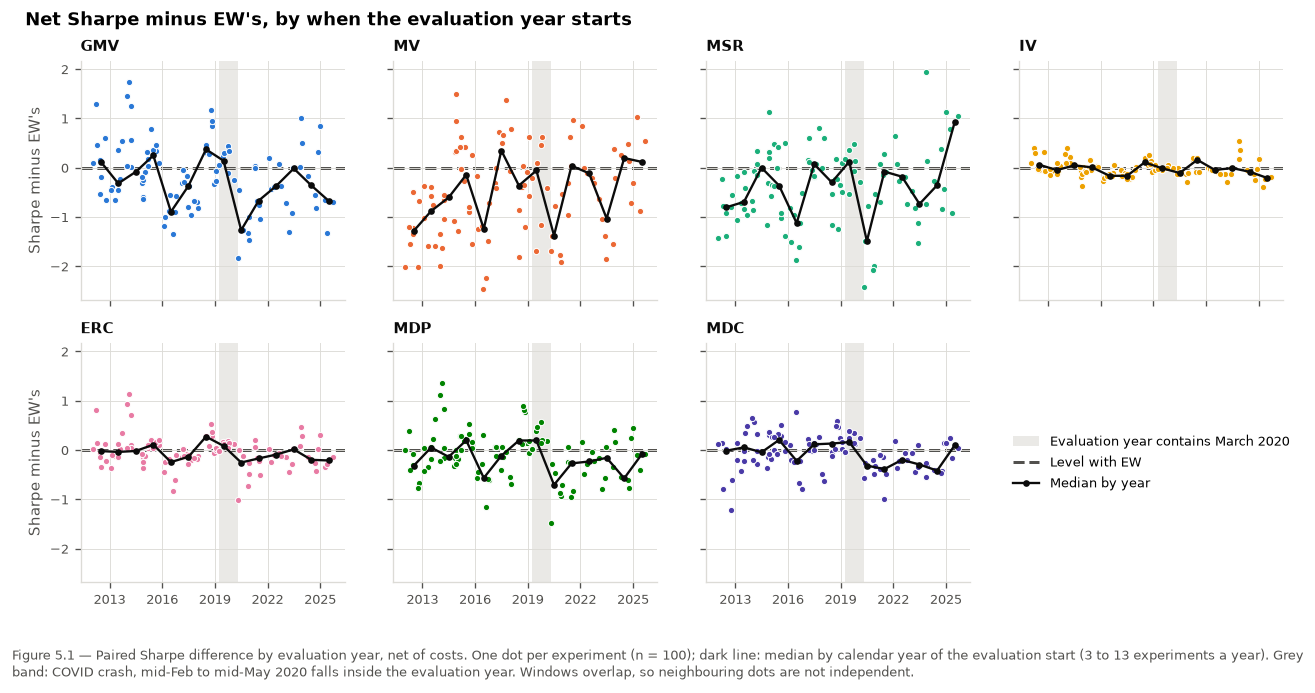

Median paired Sharpe difference by evaluation-start year:


strategy,n,GMV,MV,MSR,IV,ERC,MDP,MDC
evaluation_start,,,,,,,,
2012,8,0.12,-1.29,-0.80,0.06,-0.02,-0.32,-0.02
2013,8,-0.32,-0.88,-0.69,-0.05,-0.04,0.05,0.05
2014,10,-0.08,-0.61,-0.00,0.05,-0.02,-0.14,-0.05
2015,10,0.25,-0.15,-0.36,0.01,0.11,0.19,0.20
2016,7,-0.90,-1.24,-1.13,-0.17,-0.25,-0.57,-0.22
2017,9,-0.37,0.35,0.07,-0.17,-0.14,-0.12,0.11
2018,8,0.37,-0.36,-0.30,0.11,0.27,0.19,0.13
2019,8,0.14,-0.06,0.12,-0.01,0.08,0.19,0.16
2020,7,-1.27,-1.38,-1.49,-0.11,-0.25,-0.71,-0.32


In [4]:
crisis = rb.crisis_exposure(experiments)
eval_start = experiments["evaluation_start"]
crash_starts = eval_start[crisis == "In evaluation year"]

fig, axes = viz.paired_by_date(d_sharpe, eval_start, shade=(crash_starts.min(), crash_starts.max()),
                               shade_label="Evaluation year contains March 2020")
fig.suptitle("Net Sharpe minus EW's, by when the evaluation year starts", x=0.01, ha="left",
             fontsize=11, fontweight="bold", y=1.02)
viz.caption(axes[1, 0], f"Figure 5.1 — Paired Sharpe difference by evaluation year, net of costs. One dot per "
                        f"experiment (n = {len(d_sharpe)}); dark line: median by calendar year of the evaluation start "
                        f"(3 to 13 experiments a year). Grey band: {STRESS_LABEL} falls inside the evaluation year. "
                        "Windows overlap, so neighbouring dots are not independent.")
plt.show()

by_year = d_sharpe.groupby(eval_start.dt.year).median()
by_year.insert(0, "n", eval_start.dt.year.value_counts().sort_index())
print("Median paired Sharpe difference by evaluation-start year:")
display(fmt.style(by_year, {"n": fmt.count, **{s: (lambda v: fmt.number(v, 2)) for s in d_sharpe.columns}}))

**No strategy's standing against EW drifts much over time.** IV and ERC have yearly medians within
about 0.3 of zero from 2012 to 2025, and MDC within about 0.4. If anything, ERC sits slightly below
zero in most evaluation years starting since 2021, but on only 4–7 experiments a year. **What varies
is the year, and it tends to move the optimisers together.** Evaluation years starting in 2016 and
2020 are bad for all seven strategies, and those starting in 2015, 2018 and 2019 (the last contain
the crash) are good for most of them. GMV, MV and MSR swing most, which matches their
larger dispersion in Table 4.3. F3 picks up the crash directly.

---

## F3 — Crisis exposure

Experiments are grouped by where the crash (`stylised.STRESS_WINDOW`, mid-February to mid-May 2020) falls: in the
evaluation year, in the estimation period only, or neither. A one-session overlap counts, and the
evaluation year takes precedence.

In [5]:
pair_corr = rb.max_pair_correlation(prices, experiments)
pair = pd.Series(pd.Categorical(
    np.where(pair_corr > rb.COLLINEAR_THRESHOLD, f"Holds a pair > {rb.COLLINEAR_THRESHOLD}", "No such pair"),
    categories=[f"Holds a pair > {rb.COLLINEAR_THRESHOLD}", "No such pair"]), index=experiments.index)

long = rb.split_table(results, {"Crisis (March 2020)": crisis, "Near-collinear pair": pair})

def wide(measure):
    # One row per group, one column per strategy, in Table 5.2's row order.
    out = long[measure].unstack("strategy")[d_sharpe.columns]
    out.insert(0, "n", long["n"].groupby(level=["split", "group"]).first())
    return out.reindex(long.index.droplevel("strategy").unique())

period_rows = ["All experiments", "Crisis (March 2020)"]
for measure, rule in [("Beats EW (Sharpe) %", PCT(0)), ("Median Δ Sharpe", lambda v: fmt.number(v, 2)),
                      ("Lower vol %", PCT(0))]:
    print(f"{measure}, by crisis exposure:")
    t = wide(measure).loc[period_rows]
    display(fmt.style(t, {"n": fmt.count, **{s: rule for s in d_sharpe.columns}}))

Beats EW (Sharpe) %, by crisis exposure:


strategy                                         n GMV  MV MSR  IV ERC MDP MDC
split               group                                                     
All experiments     All                        100  42  30  30  39  46  45  44
Crisis (March 2020) In evaluation year           8  62  38  50  38  75  88  75
                    In estimation period only   13  23  31  31  23  31  15   8
                    Neither                     79  43  29  28  42  46  46  47

Median Δ Sharpe, by crisis exposure:


strategy                                         n    GMV     MV    MSR     IV    ERC    MDP    MDC
split               group                                                                          
All experiments     All                        100  -0.19  -0.45  -0.33  -0.04  -0.06  -0.08  -0.02
Crisis (March 2020) In evaluation year           8   0.14  -0.31   0.04  -0.01   0.12   0.19   0.20
                    In estimation period only   13  -0.67  -0.31  -0.27  -0.05  -0.17  -0.47  -0.32
                    Neither                     79  -0.17  -0.55  -0.38  -0.05  -0.07  -0.06  -0.01

Lower vol %, by crisis exposure:


strategy                                         n  GMV  MV MSR   IV  ERC  MDP  MDC
split               group                                                          
All experiments     All                        100   98   1  15  100  100   92   67
Crisis (March 2020) In evaluation year           8  100  12  75  100  100  100  100
                    In estimation period only   13   92   0   0  100  100   85   62
                    Neither                     79   99   0  11  100  100   92   65

**The crash helps the optimisers when it falls in the evaluation year, and hurts them when it falls only
in the estimation period.**

- **Crash in the evaluation year (8 experiments):** GMV, MSR, ERC, MDP and MDC beat EW in at least half
  of them, ERC in three-quarters and MDP in seven of eight. A defensive tilt pays when the crash happens
  inside the year being scored.
- **Crash in the estimation period only (13):** the reverse. ERC beats EW in under a third of these,
  GMV and IV in under a quarter, MDP in about one in seven and MDC in one. The estimates feeding these portfolios are dominated by crash-era
  volatilities and correlations, so the weights are fitted to a regime that has already passed. This
  matches §9's finding that crash windows distort the covariance estimate.
- **Neither (79):** close to the full-sample figures in Table 4.5.

**ERC's risk reduction does not depend on the period.** It has lower volatility than EW in every
experiment of every group (third table). What depends on the period is the Sharpe comparison, and
mostly through where the crash falls.

---

## F4 — Asset subset

Two cuts. First, whether the subset holds a **near-collinear pair**: two assets whose correlation over
the trailing year that ends the estimation period exceeds 0.85, the threshold notebooks 03 and 06 use.
Second, **each asset in turn**: experiments that hold it against those that don't.

In [6]:
for measure, rule in [("Beats EW (Sharpe) %", PCT(0)), ("Median Δ Sharpe", lambda v: fmt.number(v, 2)),
                      ("Lower vol %", PCT(0))]:
    print(f"{measure}, by near-collinear pair:")
    t = wide(measure).loc[["All experiments", "Near-collinear pair"]]
    display(fmt.style(t, {"n": fmt.count, **{s: rule for s in d_sharpe.columns}}))

print("Pairs are not spread evenly across periods. Experiments by pair and crisis exposure:")
display(pd.crosstab(pair.rename("pair"), crisis.rename("crisis")))
print("... and by evaluation-start year:")
display(pd.crosstab(pair.rename("pair"), eval_start.dt.year.rename("evaluation start")))

Beats EW (Sharpe) %, by near-collinear pair:


strategy                                   n GMV  MV MSR  IV ERC MDP MDC
split               group                                               
All experiments     All                  100  42  30  30  39  46  45  44
Near-collinear pair Holds a pair > 0.85   20  30  20  25  35  40  35  50
                    No such pair          80  45  32  31  40  48  48  42

Median Δ Sharpe, by near-collinear pair:


strategy                                   n    GMV     MV    MSR     IV    ERC    MDP    MDC
split               group                                                                    
All experiments     All                  100  -0.19  -0.45  -0.33  -0.04  -0.06  -0.08  -0.02
Near-collinear pair Holds a pair > 0.85   20  -0.55  -0.97  -0.66  -0.06  -0.12  -0.22  -0.04
                    No such pair          80  -0.13  -0.36  -0.28  -0.04  -0.04  -0.04  -0.02

Lower vol %, by near-collinear pair:


strategy                                   n GMV MV MSR   IV  ERC MDP MDC
split               group                                                
All experiments     All                  100  98  1  15  100  100  92  67
Near-collinear pair Holds a pair > 0.85   20  95  5  25  100  100  90  60
                    No such pair          80  99  0  12  100  100  92  69

Pairs are not spread evenly across periods. Experiments by pair and crisis exposure:


crisis,In evaluation year,In estimation period only,Neither
pair,,,
Holds a pair > 0.85,3,6,11
No such pair,5,7,68


... and by evaluation-start year:


evaluation start,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
pair,,,,,,,,,,,,,,
Holds a pair > 0.85,4,0,0,1,3,2,0,2,5,2,0,0,0,1
No such pair,4,8,10,9,4,7,8,6,2,3,5,7,4,3


In [7]:
# Separate the pair from the period: compare within the crash-free experiments only.
calm = crisis == "Neither"
rows = {}
for g in pair.cat.categories:
    m = calm & (pair == g)
    rows[(g, "Median Δ Sharpe")] = d_sharpe[m].median()
    rows[(g, "Beats EW %")] = (d_sharpe[m] > 0).mean() * 100
within = pd.DataFrame(rows).T
within.insert(0, "n", [int((calm & (pair == g)).sum()) for g, _ in within.index])
print("Crash-free experiments only (crisis = Neither), by near-collinear pair:")
display(fmt.style(within, {"n": fmt.count, **{s: (lambda v: fmt.number(v, 2)) for s in d_sharpe.columns}}))

Crash-free experiments only (crisis = Neither), by near-collinear pair:


strategy                              n    GMV     MV    MSR     IV    ERC    MDP    MDC
Holds a pair > 0.85 Median Δ Sharpe  11  -0.54  -1.21  -0.78  -0.04  -0.12  -0.12   0.04
                    Beats EW %       11  36.36  18.18  27.27  45.45  36.36  36.36  72.73
No such pair        Median Δ Sharpe  68  -0.13  -0.39  -0.35  -0.05  -0.06  -0.04  -0.01
                    Beats EW %       68  44.12  30.88  27.94  41.18  47.06  47.06  42.65

**A near-collinear pair hurts GMV, MV and MSR; for the risk-based strategies the effect is small and
partly the period.** Across all experiments, subsets with a pair look worse for every optimiser except
MDC. But the pairs cluster in particular periods (crosstabs above): 9 of the 20 have the crash in the
window (6 of them in the estimation period only, the group that is bad for the optimisers in F3),
against 12 of the 80 without a pair. Within the crash-free experiments only (11 with a pair, 68 without), IV and MDC do as well with
a pair as without, ERC and MDP somewhat worse (median Δ Sharpe −0.12 against −0.06 and −0.04, on 11
experiments), and GMV, MV and MSR still much worse. A
plausible reason: two near-identical assets with different trailing means invite a mean-based
optimiser to load on one of them. Notebook 06 found that the pairs do not raise turnover, so any harm
comes through the weights, not through trading costs.

### Figure 5.2 — paired results by asset held

Each cell: the share of experiments in which the strategy beats EW on Sharpe when the subset **holds**
the asset, minus the share when it **does not**, in percentage points. Each asset is held in about 40
of the 100 experiments, by the two-per-sector draw.

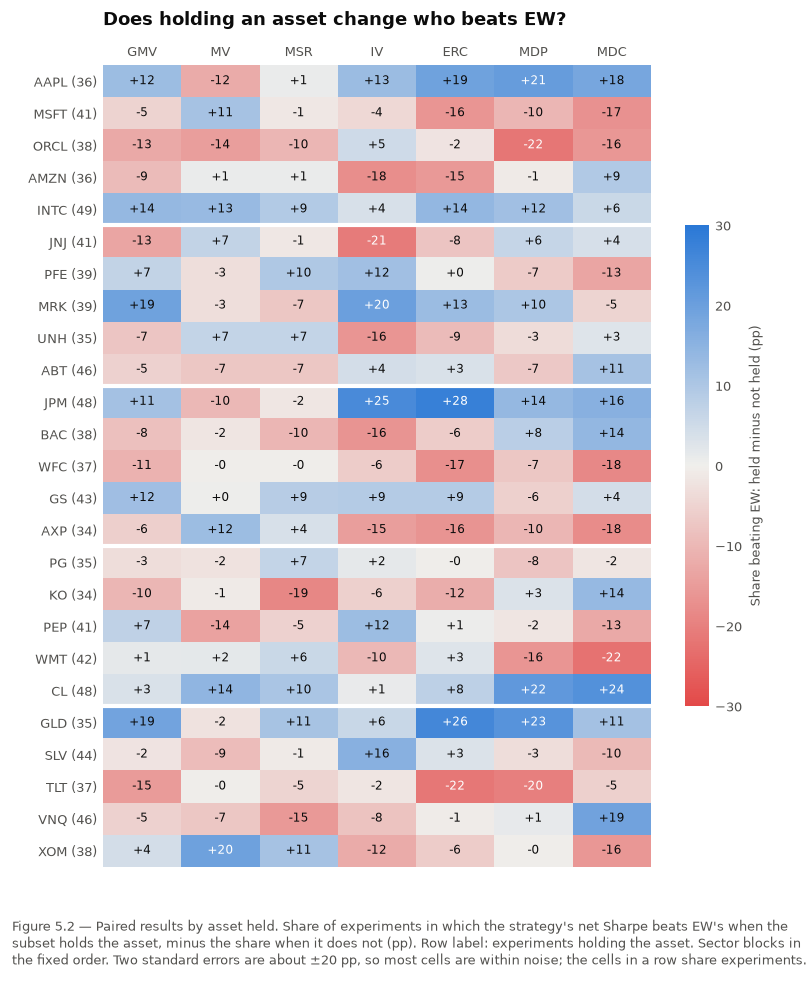

Cells beyond two standard errors: 13 of 175 (about 9 expected by chance if nothing mattered).
Two-SE yardstick, range across cells: ±18 to ±21 pp.
ERC: share with lower volatility than EW, held minus not held, ranges +0 to +0 pp across the 25 assets.
Largest Sharpe effects per strategy (pp):


,GMV,MV,MSR,IV,ERC,MDP,MDC
0,MRK +19,XOM +20,KO -19,JPM +25,JPM +28,GLD +23,CL +24
1,GLD +19,ORCL -14,VNQ -15,JNJ -21,GLD +26,ORCL -22,WMT -22
2,TLT -15,CL +14,XOM +11,MRK +20,TLT -22,CL +22,VNQ +19


In [8]:
effect, n_held = rb.asset_effect(results, experiments)

fig, ax = plt.subplots(figsize=(6.6, 7.4))
viz.asset_effect_heatmap(effect, n_held, ax=ax)
ax.set_title("Does holding an asset change who beats EW?", pad=24)
fig.tight_layout()
# Noise yardstick: two standard errors of a difference in proportions at ~40 vs ~60 experiments.
p = (d_sharpe > 0).mean()
se2 = (2 * np.sqrt(np.outer(1 / n_held, p * (1 - p)) + np.outer(1 / (len(d_sharpe) - n_held), p * (1 - p))) * 100)
se2 = pd.DataFrame(se2, index=n_held.index, columns=p.index)
viz.caption(ax, f"Figure 5.2 — Paired results by asset held. Share of experiments in which the strategy's net Sharpe "
                f"beats EW's when the subset holds the asset, minus the share when it does not (pp). Row label: "
                f"experiments holding the asset. Sector blocks in the fixed order. Two standard errors are about "
                f"±{se2.median().median():.0f} pp, so most cells are within noise; the cells in a row share experiments.")
plt.show()

beyond = (effect.abs() > se2.reindex(effect.index)).to_numpy()
print(f"Cells beyond two standard errors: {beyond.sum()} of {beyond.size} "
      f"(about {0.05 * beyond.size:.0f} expected by chance if nothing mattered).")
print(f"Two-SE yardstick, range across cells: ±{se2.min().min():.0f} to ±{se2.max().max():.0f} pp.")

vol_effect = pd.DataFrame({a: ((d_vol < 0)[h].mean() - (d_vol < 0)[~h].mean()) * 100
                           for a, h in rb.holdings(experiments).items()}).T
print(f"{RECOMMENDED}: share with lower volatility than EW, held minus not held, ranges "
      f"{vol_effect[RECOMMENDED].min():+.0f} to {vol_effect[RECOMMENDED].max():+.0f} pp across the 25 assets.")
print("Largest Sharpe effects per strategy (pp):")
display(pd.DataFrame({s: effect[s].abs().nlargest(3).index.map(lambda a: f"{a} {effect.loc[a, s]:+.0f}")
                      for s in effect.columns}))

**No single asset decides the result.** The number of cells beyond two standard errors is close to
what chance alone would give (printed above), and the cells in a row are not independent: they share
the same experiments. The patterns that repeat across strategies are in the **defensive block**:
subsets holding `GLD` favour GMV, ERC and MDP, and subsets holding `TLT` work against GMV and ERC.
`JPM` favours IV and ERC. These are patterns in which name was drawn within a sector, not evidence
about any one asset, and they are reported, not explained. **ERC's lower volatility does not depend
on which assets are drawn**: it is lower than EW's whether or not the subset holds any given asset
(printed above).

---

## Table 5.2 — sensitivity to period and subset

The main-report table: the share of experiments in which each strategy beats EW on net Sharpe, for
every group of F3 and F4. Appendix Table A5.1 adds the median difference and the share with lower
volatility.

In [9]:
table_5_2 = wide("Beats EW (Sharpe) %")
print("Table 5.2 - Sensitivity to period and subset. Share of experiments in which the strategy's net Sharpe "
      "beats EW's in the same experiment (%), by group. Groups are small; differences of 10-20 points can be noise. "
      f"Crisis: {STRESS_LABEL}. Pair: two assets correlated above {rb.COLLINEAR_THRESHOLD} over the trailing "
      "year that ends the estimation period.")
display(fmt.style(table_5_2, {"n": fmt.count, **{s: PCT(0) for s in d_sharpe.columns}}))

Table 5.2 - Sensitivity to period and subset. Share of experiments in which the strategy's net Sharpe beats EW's in the same experiment (%), by group. Groups are small; differences of 10-20 points can be noise. Crisis: COVID crash, mid-Feb to mid-May 2020. Pair: two assets correlated above 0.85 over the trailing year that ends the estimation period.


strategy                                         n GMV  MV MSR  IV ERC MDP MDC
split               group                                                     
All experiments     All                        100  42  30  30  39  46  45  44
Crisis (March 2020) In evaluation year           8  62  38  50  38  75  88  75
                    In estimation period only   13  23  31  31  23  31  15   8
                    Neither                     79  43  29  28  42  46  46  47
Near-collinear pair Holds a pair > 0.85         20  30  20  25  35  40  35  50
                    No such pair                80  45  32  31  40  48  48  42

In [10]:
table_a5_1 = long.drop(columns="Beats EW (Sharpe) %")
print("Table A5.1 - Table 5.2's groups, median paired Sharpe difference with EW and share of experiments with "
      "lower volatility than EW (%). Net of costs.")
display(fmt.style(table_a5_1, {"n": fmt.count, "Median Δ Sharpe": lambda v: fmt.number(v, 2),
                               "Lower vol %": PCT(0)}))

Table A5.1 - Table 5.2's groups, median paired Sharpe difference with EW and share of experiments with lower volatility than EW (%). Net of costs.


n Median Δ Sharpe Lower vol %
split               group                     strategy                                 
All experiments     All                       GMV       100           -0.19          98
                                              MV        100           -0.45           1
                                              MSR       100           -0.33          15
                                              IV        100           -0.04         100
                                              ERC       100           -0.06         100
                                              MDP       100           -0.08          92
                                              MDC       100           -0.02          67
Crisis (March 2020) In evaluation year        GMV         8            0.14         100
                                              MV          8           -0.31          12
                                              MSR         8            0.04          75
                                              IV          8           -0.01         100
                                              ERC         8            0.12         100
                                              MDP         8            0.19         100
                                              MDC         8            0.20         100
                    In estimation period only GMV        13           -0.67          92
                                              MV         13           -0.31           0
                                              MSR        13           -0.27           0
                                              IV         13           -0.05         100
                                              ERC        13           -0.17         100
                                              MDP        13           -0.47          85
                                              MDC        13           -0.32          62
                    Neither                   GMV        79           -0.17          99
                                              MV         79           -0.55           0
                                              MSR        79           -0.38          11
                                              IV         79           -0.05         100
                                              ERC        79           -0.07         100
                                              MDP        79           -0.06          92
                                              MDC        79           -0.01          65
Near-collinear pair Holds a pair > 0.85       GMV        20           -0.55          95
                                              MV         20           -0.97           5
                                              MSR        20           -0.66          25
                                              IV         20           -0.06         100
                                              ERC        20           -0.12         100
                                              MDP        20           -0.22          90
                                              MDC        20           -0.04          60
                    No such pair              GMV        80           -0.13          99
                                              MV         80           -0.36           0
                                              MSR        80           -0.28          12
                                              IV         80           -0.04         100
                                              ERC        80           -0.04         100
                                              MDP        80           -0.04          92
                                              MDC        80           -0.02          69

---

## F5 — Table 5.3, concentration

How many assets each strategy really holds. For each run, the weights held at every close of the
evaluation year (drift included) give a daily maximum weight and effective number of assets,
N_eff = 1 / Σwᵢ², averaged over the year. The table averages those across the 100 experiments. Each
subset holds 10 assets, so EW's N_eff is 10, less a little drift between rebalances. *Lowest effective
N* is the least diversified single run. *Days in one asset* is the share of evaluation days with more
than 99% in one asset.

In [11]:
conc = rb.concentration(grid)
table_5_3 = rb.concentration_table(conc)
print("Table 5.3 - Concentration. Weights held at each close of the evaluation year, drift included: per run the "
      f"yearly average, then the mean across the {cfg.N_EXPERIMENTS} experiments. Effective N = 1 / sum of squared "
      f"weights; {cfg.SUBSET_SIZE} assets per subset.")
display(fmt.style(table_5_3, {"Mean max weight %": PCT(1), "Mean effective N": lambda v: fmt.number(v, 1),
                              "Lowest effective N": lambda v: fmt.number(v, 1), "Days in one asset %": PCT(1)}))

Table 5.3 - Concentration. Weights held at each close of the evaluation year, drift included: per run the yearly average, then the mean across the 100 experiments. Effective N = 1 / sum of squared weights; 10 assets per subset.


,Mean max weight %,Mean effective N,Lowest effective N,Days in one asset %
strategy,,,,
EW,11.0,10.0,9.9,0.0
GMV,41.5,4.1,1.9,0.0
MV,78.7,1.6,1.0,32.3
MSR,51.5,2.9,1.4,4.0
IV,15.0,9.3,8.8,0.0
ERC,22.5,8.1,3.9,0.0
MDP,34.6,5.3,2.5,0.0
MDC,28.4,6.0,3.4,0.0


**Concentration orders the strategies the way their results do.**

- **EW, IV and ERC stay diversified.** IV holds 9.3 effective assets of 10 and ERC 8.1, with an
  average largest weight of 23% for ERC: the low-volatility defensive asset it leans on (Figure 4.4).
  No ERC run falls below about 4 effective assets.
- **MDP, MDC and GMV hold 4–6 effective assets.** GMV is the most concentrated of them, with a largest
  weight of 42% on average: the minimum-variance solution piles into the lowest-volatility assets.
- **MV and MSR are concentrated portfolios, not diversified ones.** MV holds 1.6 effective assets on
  average and is entirely in one asset on almost a third of evaluation days. MSR holds 2.9. This is
  the estimation-error shortcoming of Table 3.2, seen in the weights. It matches their wide dispersion
  (Table 4.3) and their losses when the subset holds a near-collinear pair (F4).

**ERC's lower risk does not come from concentration.** It holds almost as many effective assets as EW.

---

## F6 — Limitations

Six limitations, each with the direction in which it biases the results. For two of them the direction
can be measured from the held weights, rather than argued:

- **Hindsight:** the share of capital each strategy holds in the assets that went on to beat `SPY` over
  the panel.
- **Tax:** each strategy's distribution yield. Yahoo reinvests distributions gross of tax, so a tax
  at rate *t* costs a portfolio *t* times its yield.

Both are evaluation-year averages of the held weights, as in Table 5.3.

In [12]:
growth = panel.prices.iloc[-1] / panel.prices.iloc[0]
winners = (growth[cfg.ASSET_ORDER] > growth[cfg.PERFORMANCE_BENCHMARK]).astype(float)
in_winners = rb.weighted_exposure(grid, winners) * 100

close_unadj, dividends, splits = data.download_unadjusted()
income = data.adjustment_table(panel, close_unadj, dividends, splits, tickers=cfg.ASSET_ORDER)["Distributions pp/yr"]
yield_pp = rb.weighted_exposure(grid, income)

table_a5_2 = pd.DataFrame({
    "In winners %": in_winners.mean(),
    "In winners vs EW pp": in_winners.sub(in_winners["EW"], axis=0).median(),
    "Yield pp/yr": yield_pp.mean(),
    "Yield vs EW pp": yield_pp.sub(yield_pp["EW"], axis=0).median(),
}).reindex(cfg.STRATEGY_ORDER)
print(f"Winners: the {int(winners.sum())} assets whose total return over the panel beat "
      f"{cfg.PERFORMANCE_BENCHMARK}'s: {', '.join(winners[winners > 0].index)}.")
print("Table A5.2 - Exposure behind two limitations. Evaluation-year average of the held weights: capital in the "
      "winners (%) and distribution yield (pp/yr, Table 1.3); mean across experiments, and the median "
      "per-experiment difference from EW.")
display(fmt.style(table_a5_2, {"In winners %": PCT(1), "In winners vs EW pp": lambda v: fmt.number(v, 1),
                               "Yield pp/yr": lambda v: fmt.number(v, 2), "Yield vs EW pp": lambda v: fmt.number(v, 2)}))

print(f"Evaluation years start in {eval_start.dt.year.nunique()} distinct calendar years, "
      f"{eval_start.min().date()} to {eval_start.max().date()}; "
      f"{int((crisis == 'In evaluation year').sum())} evaluation years contain {STRESS_LABEL}.")
print(f"Panel starts {panel.prices.index[0].date()}. Deepest EW drawdown in any evaluation year: "
      f"{results[('net', 'max_dd')].xs('EW', level='strategy').min() * 100:.1f}%.")

Winners: the 6 assets whose total return over the panel beat SPY's: AAPL, MSFT, AMZN, UNH, JPM, AXP.
Table A5.2 - Exposure behind two limitations. Evaluation-year average of the held weights: capital in the winners (%) and distribution yield (pp/yr, Table 1.3); mean across experiments, and the median per-experiment difference from EW.


,In winners %,In winners vs EW pp,Yield pp/yr,Yield vs EW pp
strategy,,,,
EW,23.2,0.0,2.42,0.00
GMV,7.8,-15.8,2.42,0.16
MV,47.2,21.4,2.02,-0.42
MSR,31.4,4.8,2.31,-0.17
IV,18.6,-4.6,2.52,0.11
ERC,17.0,-5.6,2.40,0.05
MDP,15.8,-6.0,2.15,-0.23
MDC,20.5,-1.5,2.09,-0.28


Evaluation years start in 14 distinct calendar years, 2012-01-13 to 2025-09-15; 8 evaluation years contain COVID crash, mid-Feb to mid-May 2020.
Panel starts 2010-01-04. Deepest EW drawdown in any evaluation year: -31.6%.


**Draft section for the report.** Each limitation states which way it pushes the results.

1. **The 100 experiments are not 100 independent tests.** The evaluation years start in 14 calendar
   years, and two subsets share a median of 4 of their 10 assets (notebook 03), so a single market
   episode counts many times: the March 2020 crash sits in 8 evaluation years. *Direction:* no bias
   in the medians or win rates as descriptions of these samples, but they **overstate precision**. A
   win rate of 53% against 47% is not evidence of a difference, and the report runs no significance
   test on them.
2. **Survivorship and hindsight.** The universe is today's large caps, chosen in 2026. No firm that
   failed, was taken over or shrank out of the large-cap set can enter. *Direction:* this raises
   every strategy's absolute return, and the benchmark's. **Relative to EW it works against the
   risk-based strategies:** EW holds 23% of its capital in the six assets that went on to beat the
   index, and ERC about 6 points less (Table A5.2). MV and MSR, which chase trailing means, hold more.
   So hindsight flatters EW, MV and MSR against ERC, and ERC's return shortfall against EW is
   probably overstated.
3. **One vendor, one adjustment method.** Every price is Yahoo Finance's adjusted close, with no
   second source. An adjustment error would show only through the extreme-move screen, which found
   none (Table A1.1). *Direction:* no systematic one across strategies. An undetected error would
   affect each strategy in proportion to its weight in the asset affected.
4. **Spin-offs are reinvested in the parent.** Three healthcare names spun off a business in the
   panel (Table A1.2). The series continues as if the new shares were sold and reinvested in the
   parent, whereas a real holder would have kept them. *Direction:* mixed and small. Two of the
   spun-off companies have since outperformed their parents and one has lagged, so the series
   understates a holder's return for two of the names and overstates it for the third. Each is one
   of 25 assets.
5. **Distributions are reinvested gross of tax.** *Direction:* returns are **overstated for a taxable
   investor**, by the tax rate times a portfolio yield of about 2.0–2.5 points a year (Table A5.2),
   and the `SPY` benchmark is overstated the same way. **ERC's yield equals EW's**, so taxing
   distributions would not change the comparison the recommendation rests on. The high-turnover
   optimisers yield up to 0.4 points less, so a tax would favour them by a few basis points.
6. **A panel from 2010, without 2008.** The panel starts in January 2010. Its equity stress episodes
   are the 2011 euro-area and US-downgrade sell-off, which falls only in estimation periods (the first
   evaluation year starts in January 2012), the March 2020 crash, a five-week fall followed by a fast
   recovery, and the 2022 rate shock. The deepest EW drawdown in any evaluation year is 32%. There is no prolonged bear market with correlations high
   for a year or more. *Direction:* F3 found that a crash inside the evaluation year favours the
   defensive strategies, and one in the estimation data only works against them. A 2008-style bear
   market would fall inside many evaluation years. So the sample **probably understates the
   risk-based strategies' drawdown advantage** over EW. The sign on Sharpe is uncertain, because the
   recovery would then sit in the estimation data. Absolute risk is understated for every strategy.

**Taken together, none of these limitations flatters ERC against EW in a way we can measure.**
Hindsight works against it, tax and the vendor are neutral between the two, and the missing 2008
probably hides part of its benefit. If anything, the recommendation is conservative.

---

## Do the conclusions depend on period or subset?

**Draft sentence for the report.** ERC's case rests on lower risk than EW at about the same
risk-adjusted return. **The lower risk holds in every period and every subset split.** The Sharpe
comparison with EW **does depend on the period**, mainly on where the March 2020 crash falls: the
optimisers gain on EW when the crash is in the evaluation year and lose when it sits only in the
estimation data. **It depends little on the subset**, except that GMV, MV and MSR do markedly worse when
the subset holds a near-collinear pair, **and not at all on the cost assumption** (Table 5.1). These splits are descriptive, and period and subset are not
fully separable.

---

## Done-when checks (F1–F6)

In [13]:
checks = []
checks.append(("Figure 5.1 covers every experiment and the seven strategies other than EW",
               d_sharpe.shape == (cfg.N_EXPERIMENTS, len(cfg.STRATEGY_ORDER) - 1)))
checks.append(("Crisis groups partition the 100 experiments",
               crisis.notna().all() and crisis.value_counts().sum() == cfg.N_EXPERIMENTS))
checks.append(("Pair groups partition the 100 experiments", pair.value_counts().sum() == cfg.N_EXPERIMENTS))
checks.append(("Table 5.2's 'All experiments' row matches Table 4.5's win rate",
               np.allclose(table_5_2.loc[("All experiments", "All"), list(d_sharpe.columns)].astype(float),
                           pf.paired_table(results)["Beats EW (Sharpe) %"])))
checks.append(("Every asset is held in some experiments and missing from others",
               bool(((n_held > 0) & (n_held < cfg.N_EXPERIMENTS)).all())))
checks.append(("Table 5.1 ranks the eight strategies at both cost levels, and 2x Sharpe is never above 1x",
               list(table_5_1.index) == cfg.STRATEGY_ORDER
               and (table_5_1["Net Sharpe 2x"] <= table_5_1["Net Sharpe 1x"] + 1e-12).all()))
checks.append(("Table 5.1's 1x Sharpe matches Table 4.2",
               np.allclose(table_5_1["Net Sharpe 1x"], pf.headline_table(results)["Sharpe"])))
checks.append(("The 2x runs hold exactly the 1x runs' weights",
               all(grid.runs[key].weights.equals(grid.stressed[key].weights) for key in grid.runs)))
checks.append(("Table 5.3: every effective N between 1 and the subset size, and EW's within 0.5 of it",
               bool(conc["effective_n"].between(1 - 1e-9, cfg.SUBSET_SIZE + 1e-9).all())
               and abs(table_5_3.loc["EW", "Mean effective N"] - cfg.SUBSET_SIZE) < 0.5))
checks.append(("Table A5.2 covers every strategy", bool(table_a5_2.notna().all().all())))
for label, ok in checks:
    print(f"[{'PASS' if ok else 'FAIL'}] {label}")
assert all(ok for _, ok in checks), "workstream F exit criteria not met"

[PASS] Figure 5.1 covers every experiment and the seven strategies other than EW
[PASS] Crisis groups partition the 100 experiments
[PASS] Pair groups partition the 100 experiments
[PASS] Table 5.2's 'All experiments' row matches Table 4.5's win rate
[PASS] Every asset is held in some experiments and missing from others
[PASS] Table 5.1 ranks the eight strategies at both cost levels, and 2x Sharpe is never above 1x
[PASS] Table 5.1's 1x Sharpe matches Table 4.2
[PASS] The 2x runs hold exactly the 1x runs' weights
[PASS] Table 5.3: every effective N between 1 and the subset size, and EW's within 0.5 of it
[PASS] Table A5.2 covers every strategy


---

## Handoff

| Output | Report |
| --- | --- |
| Tables 5.1–5.3, Figures 5.1–5.2 | Section 6, *Robustness checks and limitations* |
| Tables A5.1, A5.2 | Appendix |
| The draft sentence on period and subset | Section 6, and the reconsideration conditions in section 7 |
| The F6 limitations draft | Section 6, and its closing line in section 7: the measurable limitations do not flatter ERC against EW |

Workstream F is complete. Workstream G assembles the report from notebooks 01–07.